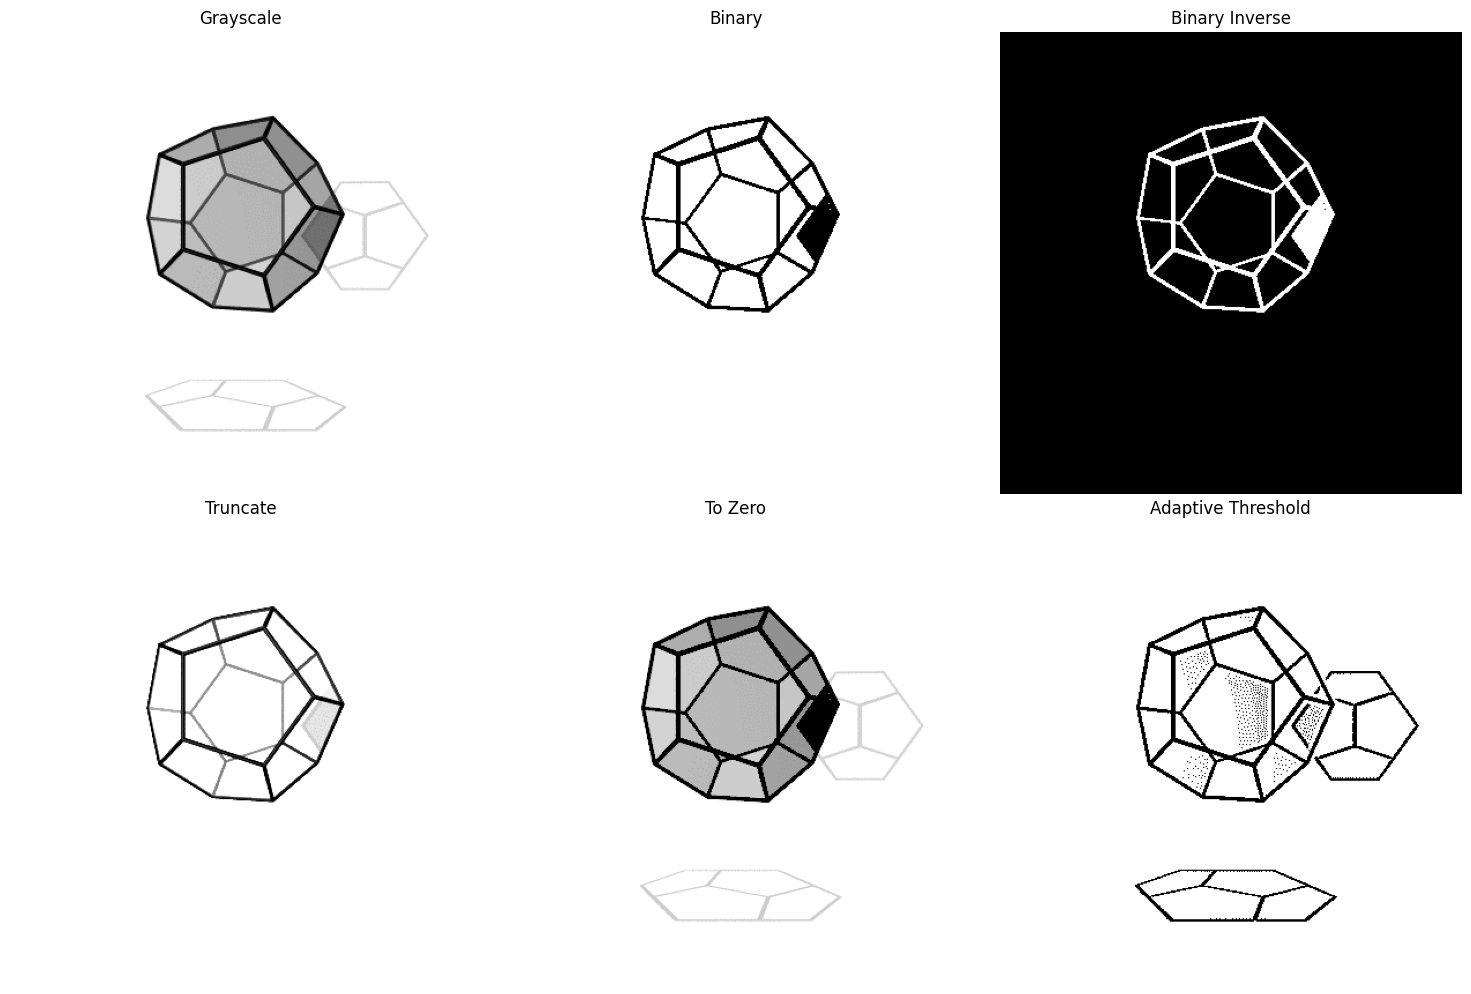

In [2]:
import cv2
import matplotlib.pyplot as plt

# Load the input image from workspace
img = cv2.imread('/content/images.png')
# Convert BGR (OpenCV default) to RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Image Thresholding

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# 1. Binary Thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# 2. Binary Inverse
_, inverse = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY_INV
)

# 3. Truncate
_, truncate = cv2.threshold(
    gray, 127, 255, cv2.THRESH_TRUNC
)

# 4. To Zero
_, tozero = cv2.threshold(
    gray, 127, 255, cv2.THRESH_TOZERO
)

# 5. Adaptive Thresholding
adaptive = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

# Display results
titles = ['Grayscale', 'Binary',
          'Binary Inverse', 'Truncate',
          'To Zero', 'Adaptive Threshold']

images = [gray, binary, inverse,
          truncate, tozero, adaptive]

plt.figure(figsize=(15, 10))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save output
for title, image in zip(titles[1:], images[1:]):
    cv2.imwrite(title.replace(' ', '_') + '.png', image)